# Generative Adversarial Networks (GAN)
Una GAN es un modelo de IA y DL que funciona mediante la competición de dos redes neuronales:
- Generador: crea datos a partir de ruido.
- Discriminador: actúa como un juez. Recibe datos reales (del entrenamiento) y falsos (del generador) y tiene que adivinar cuáles son reales y cuáles son falsos.

Ambas redes se entrenan a la vez: el generador aprende a crear resultados cada vez más realistas para engañar al discriminador, y el discriminador se vuelve más estricto y preciso para no dejarse engañar. Este bucle se detiene cuando el generador produce datos tan reales que el discriminador ya no puede distinguir lo real de lo falso.

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchmetrics.image.inception import InceptionScore
from torchmetrics.image.fid import FrechetInceptionDistance
import matplotlib.pyplot as plt
from tqdm import tqdm
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

cuda


## Carga y preprocesado de datos
Vamos a normalizar los datos al rango [-1,1] ya que la función de salida es la tanh utilizada en la capa de salida del Generator. Además, al no necesitar conjunto de test, usaremos ese conjunto como conjunto de validación.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train = datasets.MNIST("../data", train=True, download=True, transform=transform)
val = datasets.MNIST("../data", train=False, download=True, transform=transform)

train_dataloader = DataLoader(train, batch_size=128, shuffle=True)
val_dataloader = DataLoader(val, batch_size=128, shuffle=True)

## Generator
El Generator transforma un vector de ruido z a un espacio de 784 dimensiones (28x28 píxeles).

In [3]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_dim=28*28):
        super(Generator, self).__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, img_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

## Discriminator
El Discriminator recibe un vector de 784 elementos y devuelve un único valor que representa la probabilidad de que la imagen sea real.

In [4]:
class Discriminator(nn.Module):
    def __init__(self, img_dim=28*28):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

## Training loop
Definimos ahora una función de entrenamiento auxiliar parametrizable. A diferencia de TensorFlow que automatiza todo el proceso (model.fit()), con PyTorch tenemos más libertad para controlar el flujo del entrenamiento. A pesar de ser una función larga, su estructura es simple.

- **Entrenamiento de Discriminator**: se evalúan imágenes reales (y=1) y falsos (y=0).
- **Entrenamiento de Generator**: se reevalúan las imágenes falsas a través del Discriminator con etiquetas objetivo invertidas (y=1), forzando a G a ajustar sus parámetros para corregir sus errores.

In [5]:
def learning_loop(train_dataloader, val_dataloader, generator, discriminator, epochs, loss_fn, lr, opt_generator, opt_discriminator, val_freq, device):
    train_loss_gen, train_loss_dis, val_loss_dis, val_loss_gen = [], [], [], [] # almacenamos los errores de cada epoca para ambas redes en train y val

    opt_gen = opt_generator(generator.parameters(), lr=lr, betas=(0.5, 0.999)) # creamos los optimizadores para cada red
    opt_dis = opt_discriminator(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

    with tqdm(range(epochs), desc="epoch") as pbar:
        for epoch in pbar: # para cada epoca
            generator.train()
            discriminator.train()
            train_step_loss_gen, train_step_loss_dis = [], [] # almacenamos los errores del paso actual
            for real, _ in train_dataloader: # para cada batch
                real = real.reshape(-1, 28*28).to(device) # pasamos la imagen del formato (batch, 28, 28) a (batch, 28*28)
                batch_size = real.size(0) # obtenemos el tamaño del batch

                label_real = torch.ones(batch_size, 1, device=device) # creamos una lista de 1s para indicar imagenes reales
                label_fake = torch.zeros(batch_size, 1, device=device) # creamos una lista de 0s para indicar imagenes falsas

                opt_dis.zero_grad() # reseteamos los gradientes a 0
                noise = torch.randn(batch_size, generator.z_dim, device=device) # generamos ruido para el generator
                fake = generator(noise) # creamos la imagen
                loss_dis_real = loss_fn(discriminator(real), label_real) # evaluamos las imagenes reales (tiene que dar 1)
                loss_dis_fake = loss_fn(discriminator(fake.detach()), label_fake) # evaluamos las falsas (tiene que dar 0)
                loss_dis = (loss_dis_real + loss_dis_fake) / 2 # hacemos la media de los errores obtenidos

                loss_dis.backward() # calculamos los gradientes
                opt_dis.step() # ajustamos los parametros del modelo usando los gradientes calculados
                train_step_loss_dis.append(loss_dis.item()) # añadimos el error del paso actual

                opt_gen.zero_grad() # reseteamos los gradientes a 0
                output = discriminator(fake) # obtenemos la salida de la imagen falsa
                loss_gen = loss_fn(output, label_real) # medimos el error de que tanto ha fallado el generator para engañar al discriminator

                loss_gen.backward() # calculamos los gradientes
                opt_gen.step() # ajustamos los parametros del modelo usando los gradientes calculados
                train_step_loss_gen.append(loss_gen.item()) # añadimos el error del paso actual

            t_dis = torch.tensor(train_step_loss_dis).mean() # calculamos la media de errores de la epoca actual
            t_gen = torch.tensor(train_step_loss_gen).mean()

            train_loss_dis.append(t_dis)
            train_loss_gen.append(t_gen)

            pbar.set_postfix({"loss_dis": f"{t_dis}", "loss_gen": f"{t_gen}"})

            if epoch % val_freq == 0: # cada val_freq epocas evaluamos (es lo mismo que arriba pero sin modificar la red)
                generator.eval()
                discriminator.eval()
                val_step_loss_dis, val_step_loss_gen = [], []
                with torch.no_grad():
                    for real_val, _ in val_dataloader:
                        real_val = real_val.reshape(-1, 28*28).to(device)
                        batch_size_val = real_val.size(0)

                        label_real_val = torch.ones(batch_size_val, 1, device=device)
                        label_fake_val = torch.zeros(batch_size_val, 1, device=device)

                        noise_val = torch.randn(batch_size_val, generator.z_dim, device=device)
                        fake_val = generator(noise_val)
                        loss_dis_val_real = loss_fn(discriminator(real_val), label_real_val)
                        loss_dis_val_fake = loss_fn(discriminator(fake_val), label_fake_val)
                        loss_dis_val = (loss_dis_val_real + loss_dis_val_fake) / 2

                        output_val = discriminator(fake_val)
                        loss_gen_val = loss_fn(output_val, label_real_val)

                        val_step_loss_dis.append(loss_dis_val.item())
                        val_step_loss_gen.append(loss_gen_val.item())

                v_disc = torch.tensor(val_step_loss_dis).mean()
                v_gen = torch.tensor(val_step_loss_gen).mean()

                val_loss_dis.append(v_disc)
                val_loss_gen.append(v_gen)

    return generator, discriminator, train_loss_gen, train_loss_dis, val_loss_gen, val_loss_dis # devolvemos los modelos entrenados y los errores


## Configuración de hiperparámetros e inicio del entrenamiento
Ya teniendo nuestro bucle definido, vamos a definir los parámetros a continuación y empezar el entrenamiento.

In [6]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

lr = 0.0002
epochs = 50
loss_fn = nn.BCELoss()
opt_generator = torch.optim.Adam
opt_discriminator = torch.optim.Adam
generator = Generator(z_dim=100).to(device)
discriminator = Discriminator().to(device)
val_freq = 1

gen, dis, train_loss_gen, train_loss_dis, val_loss_gen, val_loss_dis = learning_loop(
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    generator=generator,
    discriminator=discriminator,
    epochs=epochs,
    loss_fn=loss_fn,
    lr=lr,
    opt_generator=opt_generator,
    opt_discriminator=opt_discriminator,
    val_freq=val_freq,
    device=device
)

epoch: 100%|██████████| 50/50 [11:24<00:00, 13.69s/it, loss_dis=0.5150354504585266, loss_gen=1.2735501527786255] 


## Evolución del entrenamiento
Ahora vamos a ver visualmente las curvas de error. Podemos ver en el resultado de la celda anterior que la pérdida es loss_dis=0.243989 y loss_gen=3.056958. Lo explicaremos ahora.

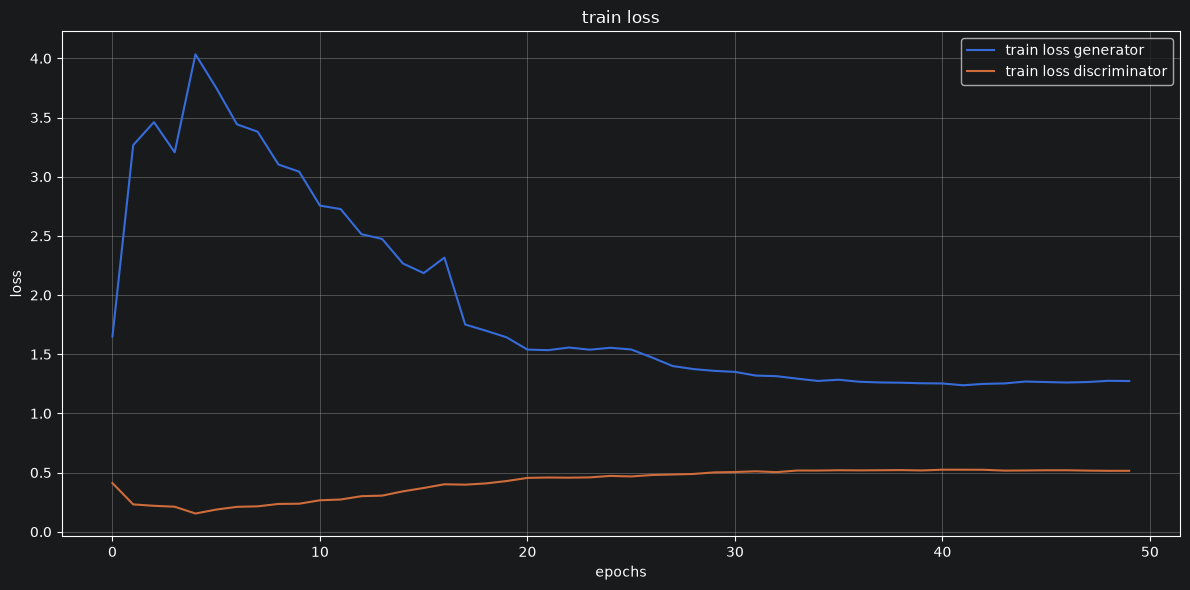

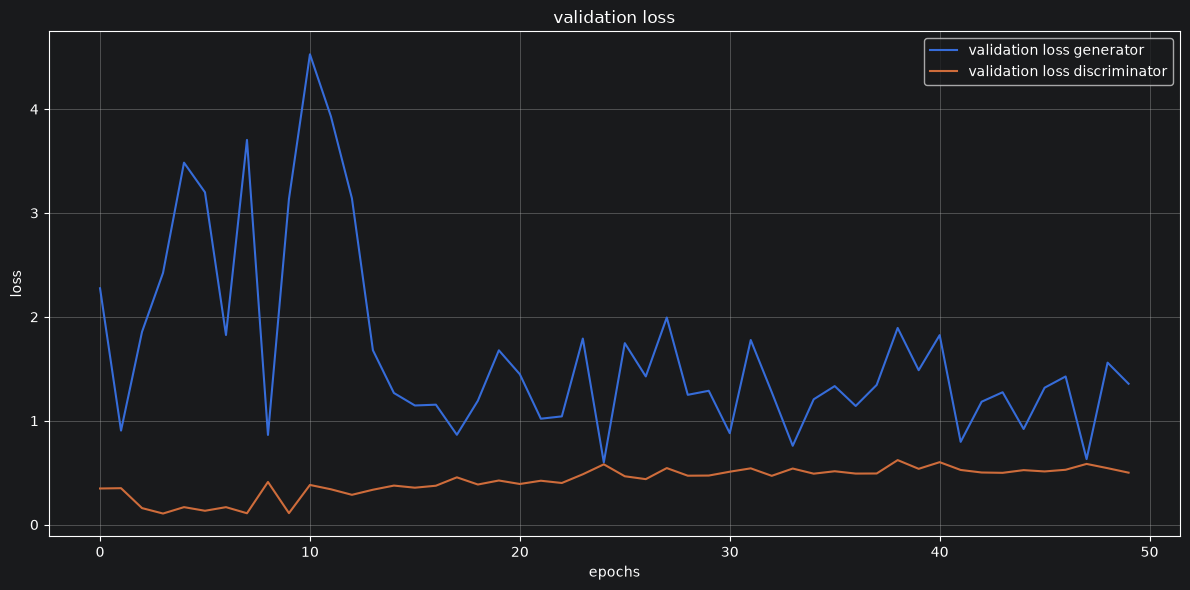

In [7]:
plt.figure(figsize=(12, 6))
plt.title("train loss")
plt.plot(range(len(train_loss_gen)), train_loss_gen, label="train loss generator")
plt.plot(range(len(train_loss_dis)), train_loss_dis, label="train loss discriminator")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.title("validation loss")
plt.plot(range(len(val_loss_gen)), val_loss_gen, label="validation loss generator")
plt.plot(range(len(val_loss_dis)), val_loss_dis, label="validation loss discriminator")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

Podemos ver que a partir de la época 15-20 las curvas del Generatos descienden muy lentamente, paralelamente la del Discriminator aumenta. Es notable que las curvas son muy inestables, con muchos picos.

El equilibrio óptimo y donde realmente la GAN converge es que ambos errores sean aproximadamente $\ln (2) \approx 0.693$. Eso es debido a que el Discriminator ya no consigue diferencia lo falso de lo real, teniendo un 50% de acertar (al azar). La función de pérdida se queda en $-\ln(0.5) = \ln(2) \approx 0.693$.

Nosotros obtenemos el error en el Discriminator de 0.244 y en Generator de 3.057. El Discriminator sigue teniendo cierta ventaja sobre el Generator (clasifica mejor que el azar).

Para mejorar los resultados se podrían añadir capas convolucionales más profundas, regularizadores, learning rate propio de cada red, entrenar el Genrator varias veces por cada actualización del Discriminator...

## Ejemplos del generador
Generamos 16 muestras a partir de vectores de ruido aleatorio no vistos durante el entrenamiento para verificar los dígitos producidos por el Generator.


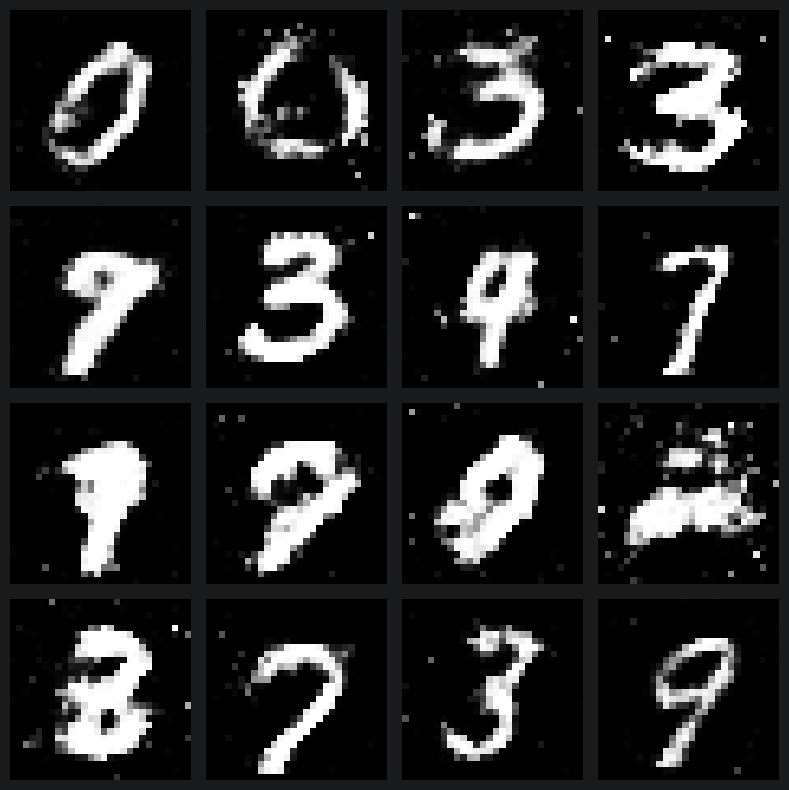

In [8]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

noise = torch.randn(16, generator.z_dim, device=device)

generator.eval()
with torch.no_grad():
    fakes = generator(noise).cpu()

fakes = fakes.reshape(16, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for img, ax in zip(fakes, axes.flatten()):
    ax.imshow((img + 1) / 2, cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

Podemos ver que la mayoría de imágenes son una simple línea, con mucho ruido de fondo, bordes difuminados en la mayoría de casos y pocos dígitos distinguibles.

## Métricas
Para complementar la evaluación visual, calculamos métricas utilizando la red preentrenada Inception-v3:

1. **Inception Score (IS)**: evalúa la claridad de los objetos generados y la diversidad entre clases. Un valor más alto indica mayor calidad. Rango de 1 a N (N es el número de clases del dataset).
2. **Fréchet Inception Distance (FID)**: compara la distribución de características extraídas de las imágenes reales frente a las generadas. Un valor más bajo indica mayor similitud con el conjunto real. Rango de 0 a $\infty$.

Vamos a crear una función auxiliar para adaptar las imágenes al formato requerido por la red Inception-v3:
- Rango [0, 255] con tipo de dato torch.uint8.
- Transformación de 1 canal (escala de grises) a 3 canales (RGB).
- Escalado espacial a resolución de 299x299 píxeles.

Usaremos un total de 10000 imágenes (el conjunto de validación) para obtener las métricas anteriores.


In [9]:
def prepare_images(images):
    if images.ndim == 2:      # Forma (B, 784)
        images = images.reshape(-1, 1, 28, 28)
    elif images.ndim == 3:    # Forma (B, 28, 28)
        images = images.unsqueeze(1)

    images = (images + 1) / 2.0
    images = torch.clamp(images, 0, 1)
    images = images.repeat(1, 3, 1, 1)
    images = nn.functional.interpolate(images, size=(299, 299), mode="bilinear", align_corners=False)
    images = (images * 255.0).to(torch.uint8)

    return images

In [10]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

total = 0
samples = 10000 # numero de muestras para las metricas
is_metric = InceptionScore().to(device)
fid_metric = FrechetInceptionDistance().to(device)

generator.eval()
with torch.no_grad():
    for batch, _ in val_dataloader:
        if total >= samples:
            break

        real_prep = prepare_images(batch.to(device))
        noise = torch.randn(batch.size(0), generator.z_dim, device=device)
        fake_prep = prepare_images(generator(noise))

        fid_metric.update(real_prep, real=True)
        fid_metric.update(fake_prep, real=False)
        is_metric.update(fake_prep)

        total += batch.size(0)

is_mean, is_std = is_metric.compute()
fid_score = fid_metric.compute()

print(f"Inception Score: {is_mean.item():.4f} ± {is_std.item():.4f}")
print(f"FID: {fid_score.item():.4f}")

gc.collect()
torch.cuda.empty_cache()

D:\Dev\Universidad\uma-26-27-1\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Inception Score: 2.4361 ± 0.0375
FID: 82.2812


Obtenemos un IS de 2.1061 ± 0.0237. 1 sería el peor caso (el modelo solo genera ruido o una única clase),un resultado de 2.1061 indica que la red genera al menos dos categorías bien diferenciadas. Visualmente, esto coincide con la alta presencia de dígitos con forma de línea frente al resto de números con geometrías más complejas.

En FID obtenemos un 185.8810 (lo normal sería valores de hasta 20). Este valor alto mide cuantitativamente que las imágenes están aún lejos de las reales, penalizado sobre todo por los píxeles de ruido en el fondo.

In [11]:
torch.save(generator.state_dict(), "generator.pth")
torch.save(discriminator.state_dict(), "discriminator.pth")